
# **MODULE 35.5 — MEL SPECTROGRAM AND LOG-MEL SPECTROGRAM**

🔥 **Must Know**

**Practical Lab 35D**

This is a particularly important module for your Speech Emotion Recognition project because the Log-Mel spectrogram will become one of our primary representations for CNN-based emotion classification.

In Module 35.4, we learned how Mel filter banks transform a linear-frequency power spectrum into Mel bands. Now we'll understand what happens after that transformation, how to visualize it, and how to prepare it for deep-learning models.

We'll avoid repeating the Mel-scale and triangular-filter construction.

---

## **1. Power spectrogram as input to Mel filtering**

Let's connect the operations we've already studied.

The processing pipeline is:

**Raw audio waveform**

Amplitude versus time

↓

**STFT**

Complex time-frequency representation

↓

**Power spectrogram**

Squared magnitude of STFT

↓

**Mel filter bank**

Aggregate frequency bins into Mel bands

↓

**Mel spectrogram**

Mel-band energy across time

↓

**Log-Mel spectrogram**

Logarithmically compressed Mel energy

### **Mathematical representation**

First, calculate the STFT:

$$
X(k,t)=STFT(x)
$$

Then calculate the power spectrogram:

$$
P(k,t)=|X(k,t)|^2
$$

Apply the Mel filter bank:

$$
M(b,t)=\sum_k H_b(k)P(k,t)
$$

Where:

- $k$ = FFT frequency-bin index.
- $t$ = time-frame index.
- $b$ = Mel-band index.
- $H_b(k)$ = weight of Mel filter $b$ at frequency bin $k$.
- $M(b,t)$ = Mel-band power at time $t$.

The resulting Mel spectrogram contains energy values across Mel bands and time.

![Cognitive Impairment Classification Prediction Model Using Voice Signal Analysis](https://images.openai.com/static-rsc-4/fbZb6yGmItsE9veUTqy0QVRnjdROrPjkgf7XEeQ_vYUnKVeV6HNJqua67TufGBad9egyXzhKPeQ4UzkjE60c07QR50LQMzPzhM-HKQgeeVC0zuRM7l78aDStc5AXLifgbwENaYPs3xMSjnSkGnNOXMMpDE0wDopiVCTibMV8RuM?purpose=inline)

Source: [MDPI](https://www.mdpi.com/2079-9292/13/18/3644)

**Important:** A Mel spectrogram is already a transformed spectrogram. It is not the same as the original linear-frequency STFT spectrogram.

---

## **2. Mel spectrogram**

🔥 **Must Know**

A Mel spectrogram represents how energy is distributed across Mel-frequency bands over time.

Its two dimensions are:

- Vertical axis: Mel-frequency bands.
- Horizontal axis: Time frames.
- Pixel intensity or colour: Energy in each Mel band.

![Age Prediction from Korean Speech Data Using Neural Networks with Diverse Voice Features](https://images.openai.com/static-rsc-4/XqtU08KQikz0jcFfYtLa8dFRqXlXS315fotfT8gB5jkkXhIIDW-l2IJ7zr_YXd2mryHqxGImL83BTqpYoFXLaZ64sqzEJUlBvbE-dFBwgtSykwQTh3e8VUpvoOKnnRiEab_fiTX1LkkgApKWaEhuXrkI3Yj1CH8Rch1BzKprPM8?purpose=inline)

Source: [MDPI](https://www.mdpi.com/2076-3417/15/3/1337)

Suppose we configure:

```python
N_MELS = 40
```

Our Mel spectrogram will have 40 frequency bands.

For example:

$$
M \in \mathbb{R}^{40 \times 401}
$$

This means:

- 40 Mel bands.
- 401 time frames.

The exact number of frames depends on recording length, FFT framing, hop length, and padding settings.

### **Why is this useful for SER?**

Emotion can influence multiple vocal characteristics:

- Vocal intensity.
- Spectral distribution.
- Voice quality.
- Changes in speech production over time.

A Mel spectrogram provides a time-frequency representation that a CNN can learn patterns from.

For example, rather than manually defining every emotion-related spectral pattern, a CNN can learn discriminative patterns from the two-dimensional representation.

---

## **3. Log-Mel transformation**

🔥 **Must Know**

Now comes the next transformation.

The Mel spectrogram contains power values.

These values can have a wide dynamic range: some time-frequency regions have very high energy, while others have very low energy.

We often apply logarithmic compression to make this range more manageable.

The resulting representation is called a **Log-Mel spectrogram**.

### **Mathematical representation**

$$
L(b,t)=\log(M(b,t)+\epsilon)
$$

Where:

- $M(b,t)$ = Mel spectrogram value.
- $\epsilon$ = small positive constant to avoid taking the logarithm of zero.

For example:

| Mel energy | Natural logarithm |
| ---------- | ----------------- |
| 1          | 0                 |
| 10         | 2.30              |
| 100        | 4.61              |
| 1,000      | 6.91              |

Notice that the original values increase by a factor of 10, but their logarithms increase by a constant amount.

This compresses the dynamic range.

![From Noise to Music: Analyzing Audio with Python and Librosa](https://images.openai.com/static-rsc-4/6p37JPJcIe2EPWaorYyunZ0sPPIRJE5N-2k_K4gFlNivzfGUdNS4LAcxaWTAaVmzeSDhtqmeEbKG0mmuLoA1Q7JKJSQNG8wS3D7T5Kma15mWWWRmYk1WgltSAY9qWuQhmlzDTyLM6ZrTMjRXHxoU7XRoh6WmI0KeSNPPv48ia5A?purpose=inline)

Source: [Medium](https://medium.com/@joshiprerak123/from-noise-to-music-and-analyzing-audio-with-python-and-librosa-4a4ea5b1b805)

### **Why do we need logarithmic compression?**

1. It reduces the numerical range of large energy differences.
2. It makes weaker spectral components easier to visualize alongside stronger components.
3. It produces a representation commonly used in speech and audio models.

**Important:** Log compression does not create new acoustic information. It changes the numerical scale on which the existing Mel energies are represented.

---

## **4. Power-to-decibel conversion**

🔥 **Must Know**

Instead of applying a natural logarithm directly, we commonly convert power values into decibels.

For power:

$$
\boxed{dB=10\log_{10}\left(\frac{P}{P_{\text{ref}}}\right)}
$$

Where:

- $P$ = measured power.
- $P_{\text{ref}}$ = reference power.

If we choose a reference power of 1:

$$
dB=10\log_{10}(P)
$$

For example:

| Power | Decibels |
| ----- | -------- |
| 1     | 0 dB     |
| 0.1   | -10 dB   |
| 0.01  | -20 dB   |
| 0.001 | -30 dB   |

### **Important distinction: Power versus amplitude**

For power values:

$$
dB=10\log_{10}(P)
$$

For amplitude values:

$$
dB=20\log_{10}(A)
$$

Why?

Because power is proportional to the square of amplitude.

$$
P\propto A^2
$$

Therefore:

$$
10\log_{10}(A^2)=20\log_{10}(A)
$$

Don't confuse these two conversions.

### **Python implementation**

For a Mel power spectrogram:

```python
mel_db = librosa.power_to_db(
    mel_spectrogram,
    ref=1.0
)
```

A commonly used alternative is:

```python
mel_db = librosa.power_to_db(
    mel_spectrogram,
    ref=np.max
)
```

These are not equivalent.

- `ref=1.0` uses a fixed reference.
- `ref=np.max` uses the maximum value of the supplied spectrogram as its reference.

The second representation expresses energy relative to that recording's maximum.

For comparing absolute energy levels across recordings, a per-recording maximum reference can be misleading because every recording is independently anchored to its own maximum.

We'll keep this distinction in mind for SER.

---

## **5. Dynamic range compression**

🔥 **Must Know**

Dynamic range refers to the difference between the largest and smallest values in a signal representation.

Consider a Mel spectrogram containing:

```python
1000, 500, 100, 10, 1, 0.1, 0.01
```

The values have a very wide range.

After logarithmic compression, the differences become easier to manage.

For example, using $10\log_{10}(P)$:

```python
30, 27, 20, 10, 0, -10, -20 dB
```

The large numerical range has been compressed.

### **What does `top_db` do in librosa?**

Consider:

```python
mel_db = librosa.power_to_db(
    mel_spectrogram,
    ref=np.max,
    top_db=80
)
```

`top_db=80` limits the dynamic range displayed or returned by clipping values more than 80 dB below the maximum.

For example, if the maximum is 0 dB:

- Values above -80 dB are retained.
- Values below -80 dB are clipped to -80 dB.

This is useful for visualization and often for model inputs.

**Important:** `top_db` is a clipping operation in addition to logarithmic compression. It is not the same thing as the logarithm itself.

---

## **6. Number of Mel bands**

🔥 **Must Know**

We discussed Mel-band construction in Module 35.4. Now let's understand how the number of bands affects our model input.

Suppose we have a 4-second recording at 16 kHz, with a hop length of 160 samples and centered STFT framing.

The approximate number of time frames is:

$$
T=1+\frac{64000}{160}=401
$$

The number of Mel bands determines the other dimension.

| Mel bands | Mel spectrogram shape |
| --------- | --------------------- |
| 20        | $20\times401$         |
| 40        | $40\times401$         |
| 64        | $64\times401$         |
| 80        | $80\times401$         |
| 128       | $128\times401$        |

![Audio Classification using FastAI and On-the-Fly Frequency Transforms](https://images.openai.com/static-rsc-4/n9JrzlbHwSTvi78w9f3934-Wi1AuxrmNDn2MHxn7Ar7vUm_S3FjGkntDMbE87lL2-0G3rv5tH4D7ykMcfu4gz79aIrL-yUYfdy2S16b73CQA3ZAcCFzXJ-vbcZFT6wuN6ZcjX-AU-0EiT1uhCxXpuDgwF3GLhC4CWpFWaTlBFMg?purpose=inline)

Source: [Medium](https://medium.com/data-science/audio-classification-using-fastai-and-on-the-fly-frequency-transforms-4dbe1b540f89)

### **How should we choose?**

For our SER project:

- **40 bands:** Initial baseline.
- **64 bands:** More detailed comparison.
- **80 bands:** Additional experiment if useful.

We'll start with 40 rather than immediately increasing the feature dimension.

The best number depends on the dataset, model architecture, and validation performance.



## **7. FFT size, hop length, and window length**

🔥 **Must Know**

These three parameters strongly influence the resulting spectrogram.

Let's distinguish their roles.

### **A. FFT size (`n_fft`)**

Determines the number of points used for the FFT.

For a real-valued signal, the one-sided spectrum contains:

$$
N_{\text{bins}}=\frac{n_{\text{fft}}}{2}+1
$$

For example:

| FFT size | One-sided frequency bins |
| -------- | ------------------------ |
| 256      | 129                      |
| 512      | 257                      |
| 1024     | 513                      |
| 2048     | 1025                     |

At a sampling rate of 16 kHz, the frequency-bin spacing is:

$$
\Delta f=\frac{f_s}{N_{\text{FFT}}}
$$

For 512:

$$
\Delta f=\frac{16000}{512}=31.25\text{ Hz}
$$

For 1024:

$$
\Delta f=\frac{16000}{1024}=15.625\text{ Hz}
$$

Larger FFT sizes give finer frequency-bin spacing, but the analysis window and signal's changing behaviour also matter.

### **B. Hop length (`hop_length`)**

Determines how many samples we move forward before calculating the next frame.

For a sampling rate of 16 kHz:

| Hop length | Time between frames |
| ---------- | ------------------- |
| 80         | 5 ms                |
| 160        | 10 ms               |
| 320        | 20 ms               |
| 512        | 32 ms               |

Smaller hop length means:

- More overlapping frames.
- Better temporal sampling.
- More computation and a larger representation.

Larger hop length means:

- Fewer frames.
- Lower temporal sampling.
- A smaller representation.

### **C. Window length (`win_length`)**

Determines how many samples are actually included in the analysis window before the FFT.

For example:

```python
n_fft = 512
win_length = 400
```

This means:

- 400 samples are taken for the analysis window.
- The windowed signal is zero-padded to 512 samples before the FFT.

At 16 kHz:

$$
400/16000=0.025\text{ seconds}
$$

So our window duration is 25 ms.

![Short-time FFT - MATLAB](https://images.openai.com/static-rsc-4/GSiJHIpQJGvfabwkeMqMQnEuxz68sgH4JwBH_fY7Jd3zcOBncrTukDgfI-7rgthzZH3hH7DhSs-9fHuNk4sUYop4jXX9Q0YTnijl5_HZde8DHdt4zF6kfP8T4pWr1uv9wqSlfjyZDK9O4QyLhA3fBB1rop7QgoGT8PyG8KAbdFg?purpose=inline)

Source: [MathWorks — dsp.STFT](https://in.mathworks.com/help/dsp/ref/dsp.stft.html)

### **How do the parameters work together?**

| Parameter    | Main effect                           |
| ------------ | ------------------------------------- |
| `n_fft`      | Frequency-bin resolution              |
| `win_length` | Duration of signal used in each frame |
| `hop_length` | Time spacing between frames           |
| `n_mels`     | Number of Mel frequency bands         |

For our initial SER experiment, retain:

```python
SR = 16000
N_FFT = 512
WIN_LENGTH = 400
HOP_LENGTH = 160
N_MELS = 40
```

This gives us a consistent starting configuration.

---

## **8. How parameter choices change the representation**

Let's compare three configurations.

**Configuration A — Higher temporal sampling**

```python
n_fft = 512
win_length = 400
hop_length = 80
n_mels = 40
```

Frames every 5 ms. More detailed temporal sampling.

**Configuration B — Our baseline**

```python
n_fft = 512
win_length = 400
hop_length = 160
n_mels = 40
```

Baseline

Frames every 10 ms. A practical balance for our initial experiment.

**Configuration C — Higher frequency resolution**

```python
n_fft = 1024
win_length = 800
hop_length = 160
n_mels = 80
```

Longer analysis window, finer FFT-bin spacing and more Mel bands.

Notice that changing these parameters affects the representation itself, not just its shape.

For example, increasing the window length means that each frame incorporates a longer section of speech. This can improve frequency resolution but blur rapid temporal changes.

**For SER:** We should avoid changing every parameter simultaneously during experiments. Change one or two at a time so that we can understand what caused a performance difference.

---

## **9. Fixed-size model inputs**

🔥 **Must Know**

Now let's connect Log-Mel spectrograms to deep learning.

A CNN expects consistent input dimensions when processing ordinary batches.

Suppose we use:

- Sampling rate = 16,000 Hz.
- Recording duration = 4 seconds.
- Mel bands = 40.
- Hop length = 160.
- Centered STFT.

Our Log-Mel spectrogram will have approximately:

$$
40\times401
$$

Every recording must produce the same dimensions for straightforward batching.

![Towhee Operator Task Detail](https://images.openai.com/static-rsc-4/ySmSUXbD_D20WTHHLEY2IRtU7Wfe3JT1XEbVJZ7VX_ipkBiT0zO8IF9qZo5wT2s8cwhhzpt4bEy7SYPvVYGfqaTKCL1bg-A5lefbDffqfHI2JLa7fIcv5DsA8XA35vKw_wiKrkAtfD389yHuA4EXj_jRFvaYTtDWXVfjjt8OYxI?purpose=inline)

Source: [Towhee](https://towhee.io/tasks/detail/operator?field_name=Audio&task_name=Audio-Embedding)

For a PyTorch CNN, the input tensor generally has the shape:

$$
(B,C,F,T)
$$

Where:

- $B$ = batch size.
- $C$ = input channels.
- $F$ = Mel bands.
- $T$ = time frames.

For example:

```python
(32, 1, 40, 401)
```

This represents:

- 32 audio recordings.
- 1 input channel.
- 40 Mel bands.
- 401 time frames.

### **Important distinction**

The single CNN input channel does not mean the original recording must be mono for every possible model. It means that this particular Mel representation is supplied as one image-like channel.

For our initial SER CNN, this is the representation we'll use.

---

## **10. Normalizing Mel features using training-set statistics**

🔥 **Must Know**

This is an important ML engineering concept.

Different Mel bands may have different numerical distributions.

For example:

| Mel band | Mean | Standard deviation |
| -------- | ---- | ------------------ |
| Band 1   | -12  | 5                  |
| Band 2   | -20  | 7                  |
| Band 3   | -35  | 9                  |
| Band 4   | -48  | 12                 |

We can standardize the Log-Mel values.

$$
Z=\frac{X-\mu}{\sigma+\epsilon}
$$

Where:

- $X$ = Log-Mel value.
- $\mu$ = training-set mean.
- $\sigma$ = training-set standard deviation.
- $\epsilon$ = small constant.

### **Why calculate statistics only from training data?**

Imagine we calculate the mean and standard deviation using the entire dataset, including the test set.

Then information from the test set influences our preprocessing.

This creates data leakage.

Correct workflow:

**Training set**

Calculate mean and standard deviation.

↓

**Save normalization statistics**

Use the same statistics everywhere.

↓

**Validation set**

Apply training statistics.

↓

**Test set**

Apply training statistics.

We'll implement this in the practical lab.

---

# **Practical Lab 35D — Mel Feature Notebook**

🔥 Hands-on implementation

Our objective is to generate four representations from the same recording and compare them.

1. Waveform.
2. STFT spectrogram.
3. Mel spectrogram.
4. Log-Mel spectrogram.

We'll also experiment with Mel-band counts and frame settings.

## **Step 1 — Import libraries**

```python
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
```

## **Step 2 — Load an audio recording**

Use one of your preprocessed SER recordings.

```python
audio, sr = librosa.load(
    "sample.wav",
    sr=16000,
    mono=True
)

print("Sample rate:", sr)
print("Audio duration:", len(audio) / sr)
print("Number of samples:", len(audio))
```

## **Step 3 — Visualize the waveform**

```python
plt.figure(figsize=(14, 3))

librosa.display.waveshow(
    audio,
    sr=sr
)

plt.title("Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()
```

This gives us the original time-domain representation.

## **Step 4 — Generate the STFT spectrogram**

Let's use our baseline configuration.

```python
N_FFT = 512
WIN_LENGTH = 400
HOP_LENGTH = 160

stft = librosa.stft(
    audio,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    win_length=WIN_LENGTH
)

magnitude = np.abs(stft)
power_spectrogram = magnitude ** 2

print("STFT shape:", stft.shape)
print("Power spectrogram shape:", power_spectrogram.shape)
```

Convert power into decibels:

```python
stft_db = librosa.power_to_db(
    power_spectrogram,
    ref=np.max
)
```

Visualize:

```python
plt.figure(figsize=(14, 5))

librosa.display.specshow(
    stft_db,
    sr=sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="linear"
)

plt.colorbar(format="%+2.0f dB")
plt.title("STFT Power Spectrogram")

plt.tight_layout()
plt.show()
```

## **Step 5 — Generate the Mel spectrogram**

Now apply Mel filtering to the power spectrogram.

```python
N_MELS = 40

mel_spectrogram = librosa.feature.melspectrogram(
    S=power_spectrogram,
    sr=sr,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    fmin=0,
    fmax=sr // 2
)

print("Mel spectrogram shape:", mel_spectrogram.shape)
```

Notice that we pass `S=power_spectrogram`.

This means we're supplying the previously calculated power spectrogram rather than asking librosa to calculate it again.

Visualize:

```python
plt.figure(figsize=(14, 5))

librosa.display.specshow(
    mel_spectrogram,
    sr=sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar()
plt.title("Mel Spectrogram")

plt.tight_layout()
plt.show()
```

## **Step 6 — Generate the Log-Mel spectrogram**

```python
log_mel = librosa.power_to_db(
    mel_spectrogram,
    ref=np.max,
    top_db=80
)

print("Log-Mel shape:", log_mel.shape)
```

Visualize:

```python
plt.figure(figsize=(14, 5))

librosa.display.specshow(
    log_mel,
    sr=sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel",
    vmin=-80,
    vmax=0
)

plt.colorbar(format="%+2.0f dB")
plt.title("Log-Mel Spectrogram")

plt.tight_layout()
plt.show()
```

## **Step 7 — Compare all four representations**

Let's put everything together.

```python
fig, axes = plt.subplots(
    4, 1,
    figsize=(14, 16)
)

# Waveform
librosa.display.waveshow(
    audio,
    sr=sr,
    ax=axes[0]
)

axes[0].set_title("Waveform")

# STFT
img1 = librosa.display.specshow(
    stft_db,
    sr=sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="linear",
    ax=axes[1]
)

axes[1].set_title("STFT Spectrogram")
fig.colorbar(img1, ax=axes[1], format="%+2.0f dB")

# Mel
img2 = librosa.display.specshow(
    mel_spectrogram,
    sr=sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel",
    ax=axes[2]
)

axes[2].set_title("Mel Spectrogram")
fig.colorbar(img2, ax=axes[2])

# Log-Mel
img3 = librosa.display.specshow(
    log_mel,
    sr=sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel",
    ax=axes[3]
)

axes[3].set_title("Log-Mel Spectrogram")
fig.colorbar(img3, ax=axes[3], format="%+2.0f dB")

plt.tight_layout()
plt.show()
```

![Spectrogram and the STFT — Introduction to Speech Processing](https://images.openai.com/static-rsc-4/iUlMArt50KDAlCgVSiZBs7Fp7n6gO_cRFvJz-tCgoVmPFEFrm3ba45sLw8GwmfkpUpE4xlqj0bZa3LZv89SEDJgrAlD1rweMng9pUL5lS1SmME28-UQRYDHK0B8biMT9TLfcoZRqVmT2F8DVih_es73IIUma1-S5B70YqCs0W_Q?purpose=inline)

![Train, Optimize, Analyze, Visualize and Deploy Models for Automatic Speech Recognition with NVIDIA's NeMo](https://images.openai.com/static-rsc-4/nlfLS64h2hJ4WowuO_Ys_pk98hhvZ-RmmAMjHcTkDdd02tBhuV7OOwjKqX4ZC6z10ifYlRDPnlOacwp2flvIpu2dkOF4AMIdLzxNxPUWeLocm9EHf_7skwV4ZJeV-Z09LGyMGsI0ORbvXUqLE-2XV-Lo8z-3c5WRxtmJneEiTOE?purpose=inline)

![Preprocessing the Audio Dataset - GeeksforGeeks](https://images.openai.com/static-rsc-4/RJlRUvS_SqbHdYk4PkTp-s310BhTUkSZ8Vm7w-s267aEMAbG2AY9IAwptBY2dEZ8WXlmFUrekj4V1RAQOMaYAgz09od1tGFX_1I7buXJLyS4cc5sw0tDQp_cz_lINs3CzYhcowcOxEkD5rHz4Fk_zFwXqwACw-JLgRW6BAEDvIE?purpose=inline)

**Observe the differences:**

- Waveform: amplitude changes over time.
- STFT: frequency content across time using linear frequency bins.
- Mel: frequency content grouped into Mel bands.
- Log-Mel: the Mel representation after logarithmic compression.

## **Step 8 — Experiment with different Mel-band counts**

Now we'll compare 20, 40, 64 and 80 Mel bands.

```python
mel_counts = [20, 40, 64, 80]

fig, axes = plt.subplots(
    len(mel_counts),
    1,
    figsize=(14, 14)
)

for ax, n_mels in zip(axes, mel_counts):

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        win_length=WIN_LENGTH,
        n_mels=n_mels,
        power=2.0
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max,
        top_db=80
    )

    librosa.display.specshow(
        mel_db,
        sr=sr,
        hop_length=HOP_LENGTH,
        x_axis="time",
        y_axis="mel",
        ax=ax
    )

    ax.set_title(f"{n_mels} Mel Bands")

plt.tight_layout()
plt.show()
```

Observe how the frequency representation changes as we increase the number of Mel bands.

## **Step 9 — Experiment with FFT and hop length**

Let's compare different configurations.

```python
configs = [
    {"n_fft": 256, "win_length": 200, "hop_length": 80},
    {"n_fft": 512, "win_length": 400, "hop_length": 160},
    {"n_fft": 1024, "win_length": 800, "hop_length": 160}
]

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 13)
)

for ax, config in zip(axes, configs):

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=config["n_fft"],
        win_length=config["win_length"],
        hop_length=config["hop_length"],
        n_mels=40,
        power=2.0
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max,
        top_db=80
    )

    librosa.display.specshow(
        mel_db,
        sr=sr,
        hop_length=config["hop_length"],
        x_axis="time",
        y_axis="mel",
        ax=ax
    )

    ax.set_title(
        f"FFT={config['n_fft']}, "
        f"Window={config['win_length']}, "
        f"Hop={config['hop_length']}"
    )

plt.tight_layout()
plt.show()
```

Compare:

- How does the number of time frames change?
- Which configuration captures rapid changes more closely?
- How does increasing the FFT size affect frequency resolution?
- Does increasing the window length make the representation smoother over time?

Remember that this experiment changes both FFT and window length in the third configuration. It is useful for visual comparison, but not an isolated experiment of FFT size alone.

## **Step 10 — Build a reusable Log-Mel extraction function**

We'll need this function later when creating the SER dataset.

```python
def extract_log_mel(
    file_path,
    sr=16000,
    n_fft=512,
    win_length=400,
    hop_length=160,
    n_mels=40
):

    audio, sr = librosa.load(
        file_path,
        sr=sr,
        mono=True
    )

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=n_fft,
        win_length=win_length,
        hop_length=hop_length,
        n_mels=n_mels,
        power=2.0
    )

    log_mel = librosa.power_to_db(
        mel,
        ref=1.0,
        top_db=None
    )

    return log_mel
```

Usage:

```python
log_mel = extract_log_mel(
    "sample.wav",
    n_mels=40
)

print(log_mel.shape)
```

Notice that we used `ref=1.0` and `top_db=None` here.

This gives us a consistent fixed-reference log-power representation without per-recording maximum normalization or `top_db` clipping. It is a useful starting point for dataset-level normalization.

## **Step 11 — Normalize using training-set statistics**

Let's implement the correct approach.

Assume we've already split our dataset into training, validation, and testing recordings, and converted them into Log-Mel arrays.

Each training example has shape:

```python
(n_mels, time_frames)
```

First, calculate training-set statistics:

```python
# Example: list of training Log-Mel arrays

train_log_mels = [
    extract_log_mel(path)
    for path in train_files
]

# Stack along a new recording dimension

train_stack = np.stack(train_log_mels)

print("Training shape:", train_stack.shape)
```

The expected shape is:

```python
(number_of_recordings, 40, time_frames)
```

Calculate statistics separately for each Mel band:

```python
mel_mean = train_stack.mean(
    axis=(0, 2),
    keepdims=True
)

mel_std = train_stack.std(
    axis=(0, 2),
    keepdims=True
)

mel_std = np.maximum(mel_std, 1e-6)
```

This produces one mean and standard deviation per Mel band.

Normalize:

```python
train_normalized = (
    train_stack - mel_mean
) / mel_std
```

Apply the same statistics to validation and test sets:

```python
val_normalized = (
    val_stack - mel_mean
) / mel_std

test_normalized = (
    test_stack - mel_mean
) / mel_std
```

**Critical:** Never recalculate `mel_mean` and `mel_std` using validation or test data.

Also, this example assumes all recordings have identical time dimensions. We'll ensure that through consistent preprocessing before stacking.

## **12. Important implementation considerations for our SER project**

| Decision               | Initial approach         |
| ---------------------- | ------------------------ |
| Sampling rate          | 16 kHz                   |
| Channels               | Mono                     |
| FFT size               | 512                      |
| Window length          | 400                      |
| Hop length             | 160                      |
| Mel bands              | 40                       |
| Power                  | 2.0                      |
| Log conversion         | Power to dB              |
| Dynamic range clipping | Controlled consistently  |
| Model input            | Fixed-size Log-Mel       |
| Normalization          | Training-set statistics  |

One subtle but important point: the normalization method used during training must also be used during inference. Save the training-set mean and standard deviation with the trained model.

---

## **What you should remember**

1. A power spectrogram is the input to Mel filtering.
2. A Mel spectrogram represents energy across Mel bands and time.
3. A Log-Mel spectrogram applies logarithmic compression to Mel energy.
4. `power_to_db()` converts power values into decibels.
5. `top_db` clips the dynamic range; it is separate from logarithmic conversion.
6. FFT size, window length, hop length, and Mel-band count determine the representation.
7. CNNs require consistent input dimensions for ordinary batching.
8. Normalize using training-set statistics and reuse them for validation, testing, and inference.


In [1]:
import librosa
import librosa.display

import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

In [2]:
audio, sr = librosa.load(
    "audio/raw/sample-speech-1m.mp3",
    sr=16000,
    mono=True
)

print("Sample rate:", sr)
print("Audio duration:", len(audio) / sr)
print("Number of samples:", len(audio))

Sample rate: 16000
Audio duration: 60.0054375
Number of samples: 960087


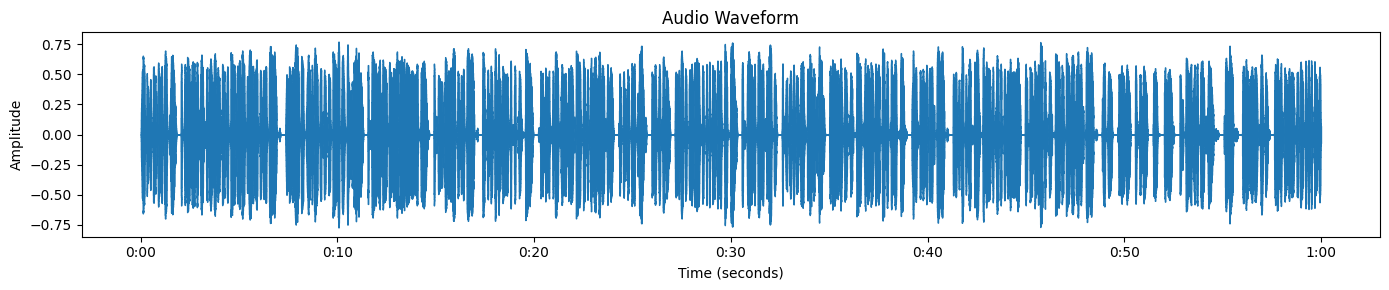

In [3]:
plt.figure(figsize=(14, 3))

librosa.display.waveshow(
    audio,
    sr=sr
)

plt.title("Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

In [4]:
N_FFT = 512
WIN_LENGTH = 400
HOP_LENGTH = 160

stft = librosa.stft(
    audio,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    win_length=WIN_LENGTH
)

magnitude = np.abs(stft)

power_spectrogram = magnitude ** 2

print("STFT shape:", stft.shape)
print("Power spectrogram shape:", power_spectrogram.shape)

STFT shape: (257, 6001)
Power spectrogram shape: (257, 6001)


In [5]:
# convert power to db 

stft_db = librosa.power_to_db(
    power_spectrogram,
    ref=np.max
)

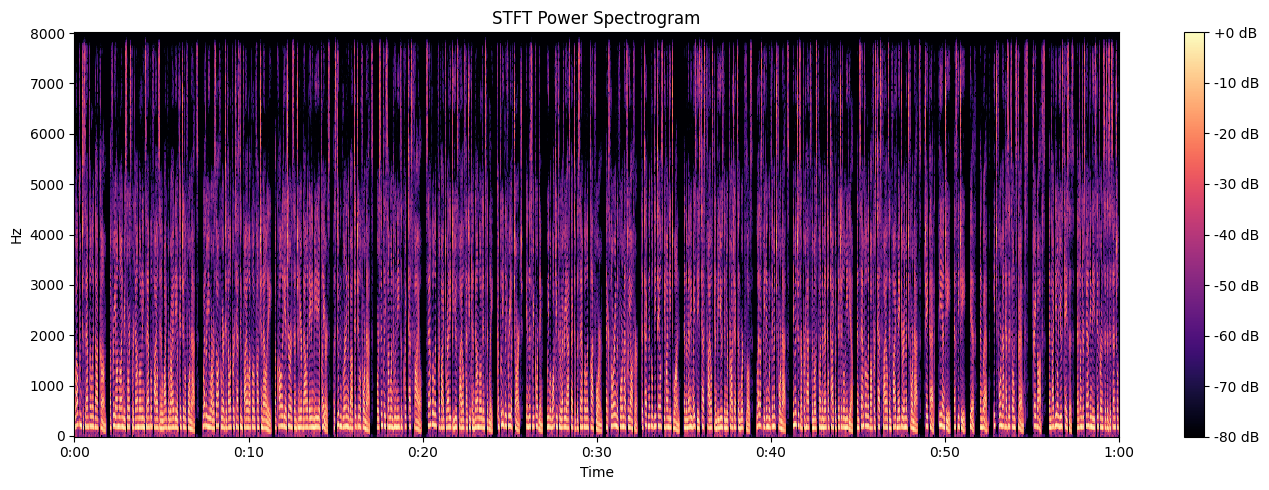

In [6]:
plt.figure(figsize=(14, 5))

librosa.display.specshow(
    stft_db,
    sr=sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="linear"
)

plt.colorbar(format="%+2.0f dB")

plt.title("STFT Power Spectrogram")

plt.tight_layout()
plt.show()

In [7]:
# Mel Spectogram 

N_MELS = 40

mel_spectrogram = librosa.feature.melspectrogram(
    S=power_spectrogram,
    sr=sr,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    fmin=0,
    fmax=sr // 2
)

print("Mel spectrogram shape:", mel_spectrogram.shape)

Mel spectrogram shape: (40, 6001)


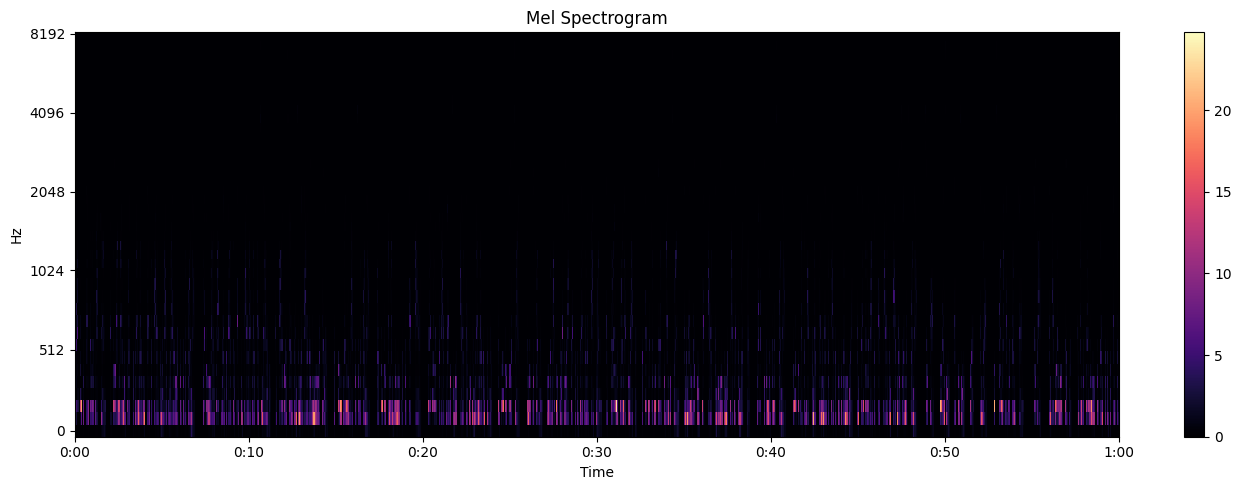

In [8]:
plt.figure(figsize=(14, 5))

librosa.display.specshow(
    mel_spectrogram,
    sr=sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar()

plt.title("Mel Spectrogram")

plt.tight_layout()
plt.show()

In [9]:
# Log-Mel 

log_mel = librosa.power_to_db(
    mel_spectrogram,
    ref=np.max,
    top_db=80
)

print("Log-Mel shape:", log_mel.shape)

Log-Mel shape: (40, 6001)


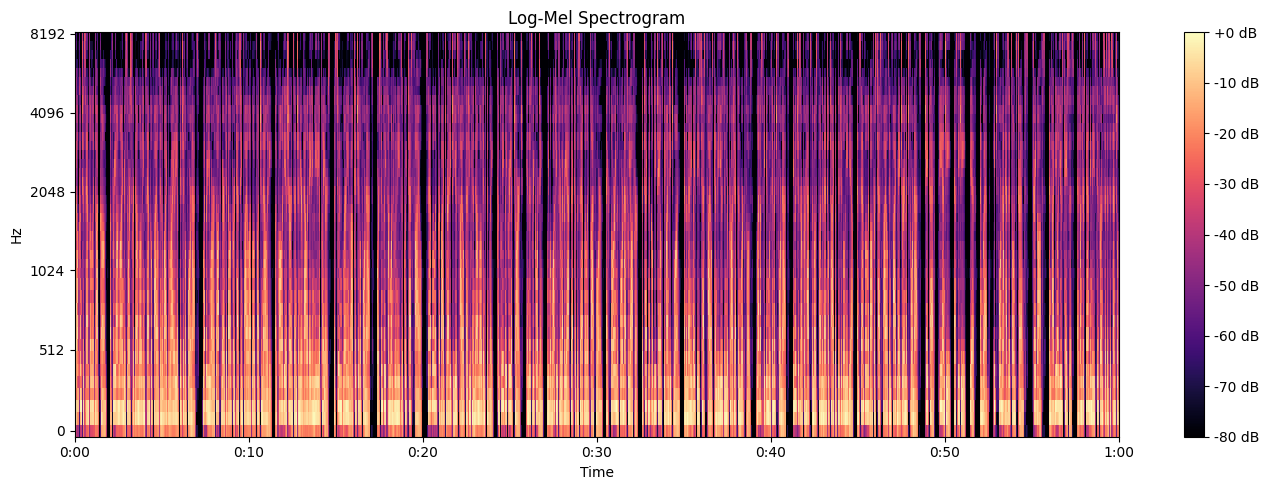

In [10]:
plt.figure(figsize=(14, 5))

librosa.display.specshow(
    log_mel,
    sr=sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel",
    vmin=-80,
    vmax=0
)

plt.colorbar(format="%+2.0f dB")

plt.title("Log-Mel Spectrogram")

plt.tight_layout()
plt.show()

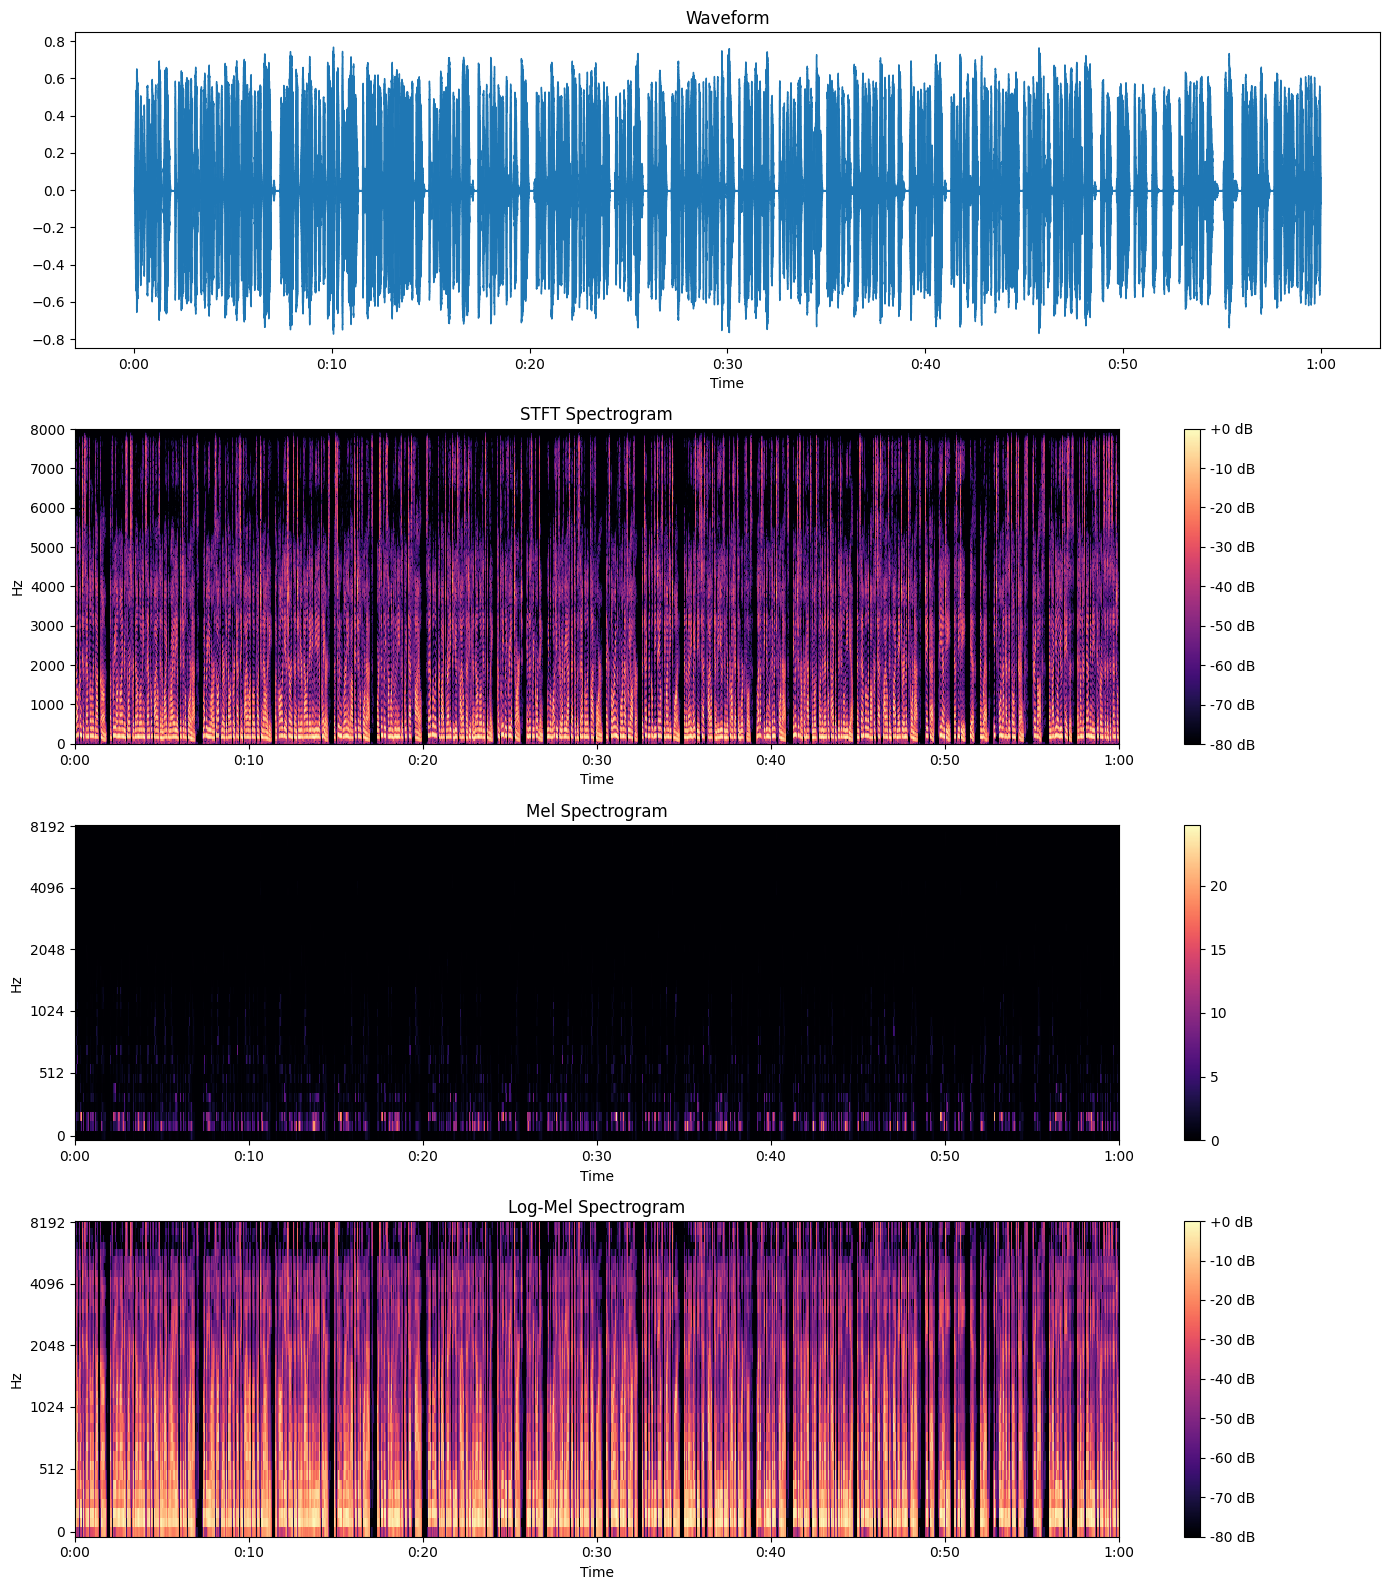

In [11]:
fig, axes = plt.subplots(
    4, 1,
    figsize=(14, 16)
)

# Waveform
librosa.display.waveshow(
    audio,
    sr=sr,
    ax=axes[0]
)

axes[0].set_title("Waveform")

# STFT
img1 = librosa.display.specshow(
    stft_db,
    sr=sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="linear",
    ax=axes[1]
)

axes[1].set_title("STFT Spectrogram")
fig.colorbar(img1, ax=axes[1], format="%+2.0f dB")

# Mel
img2 = librosa.display.specshow(
    mel_spectrogram,
    sr=sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel",
    ax=axes[2]
)

axes[2].set_title("Mel Spectrogram")
fig.colorbar(img2, ax=axes[2])

# Log-Mel
img3 = librosa.display.specshow(
    log_mel,
    sr=sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel",
    ax=axes[3]
)

axes[3].set_title("Log-Mel Spectrogram")
fig.colorbar(img3, ax=axes[3], format="%+2.0f dB")

plt.tight_layout()
plt.show()

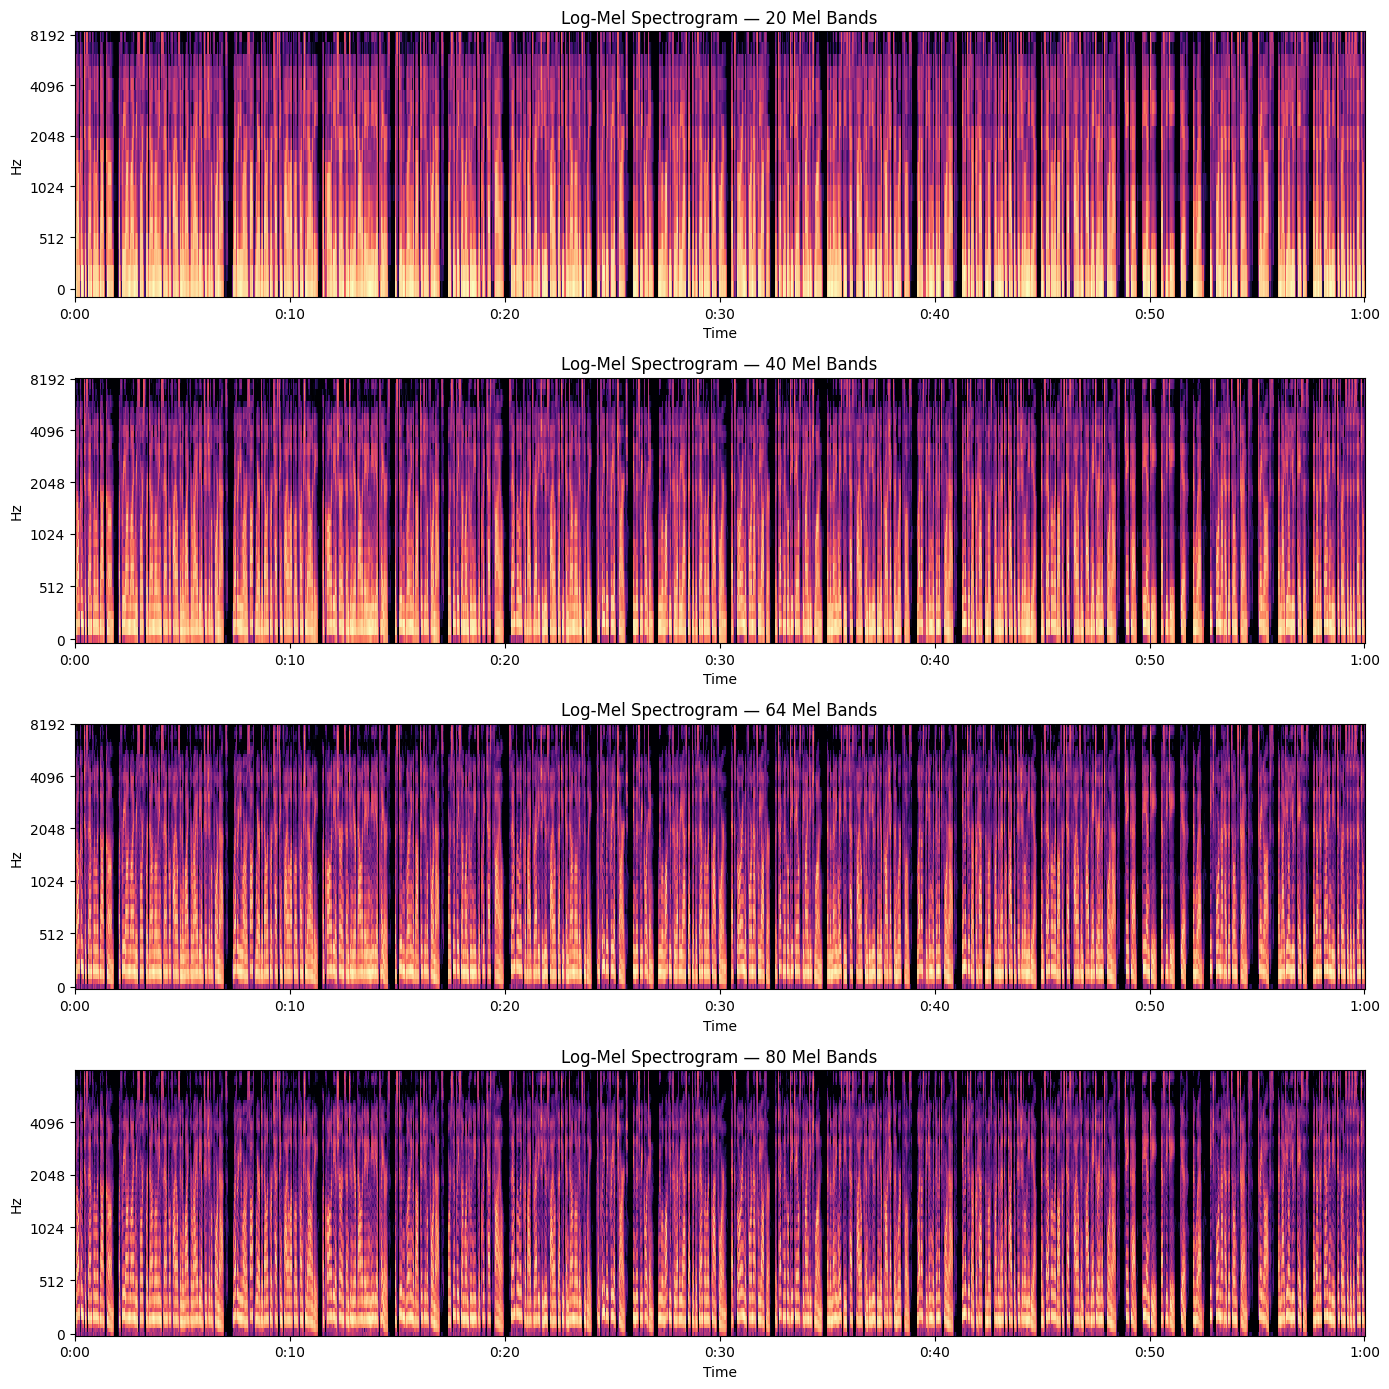

In [12]:
# Experiment with different Mel-band counts

mel_counts = [20, 40, 64, 80]

fig, axes = plt.subplots(
    len(mel_counts),
    1,
    figsize=(14, 14)
)

for ax, n_mels in zip(axes, mel_counts):

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        win_length=WIN_LENGTH,
        n_mels=n_mels,
        power=2.0
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max,
        top_db=80
    )

    librosa.display.specshow(
        mel_db,
        sr=sr,
        hop_length=HOP_LENGTH,
        x_axis="time",
        y_axis="mel",
        ax=ax
    )

    ax.set_title(f"Log-Mel Spectrogram — {n_mels} Mel Bands")

plt.tight_layout()
plt.show()

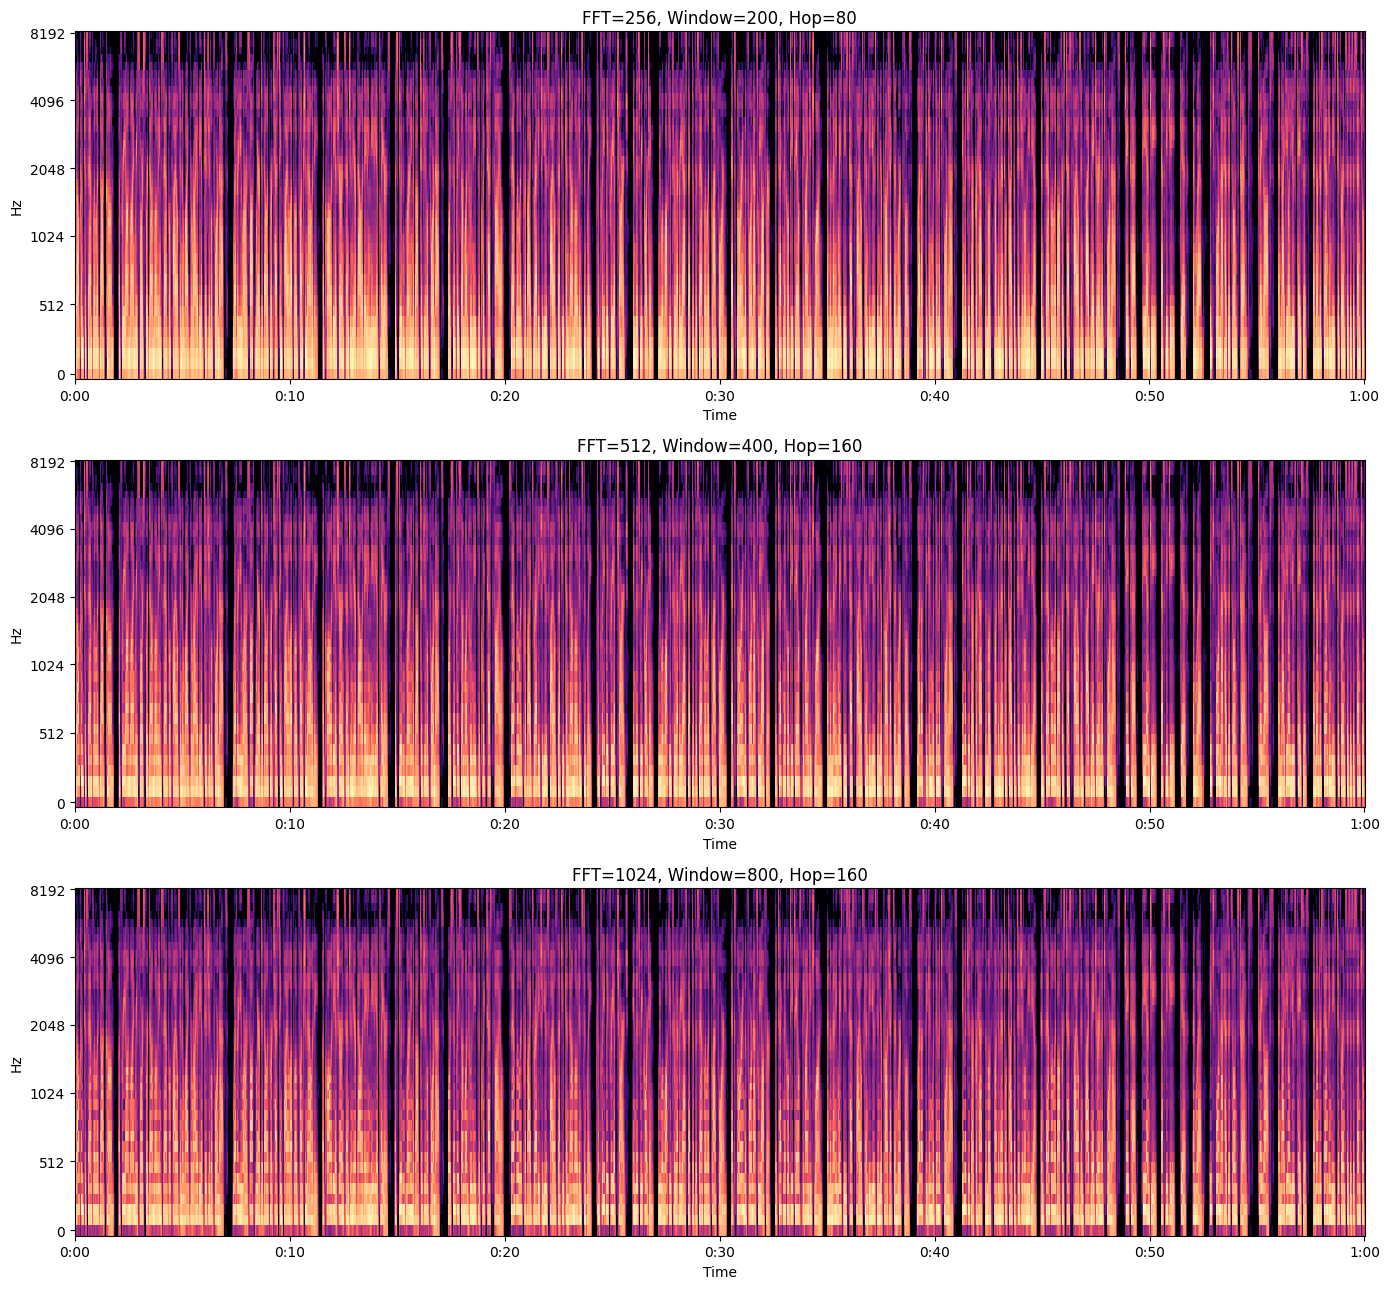

In [13]:
# Experiment with FFT and hop length

configs = [
    {"n_fft": 256, "win_length": 200, "hop_length": 80},
    {"n_fft": 512, "win_length": 400, "hop_length": 160},
    {"n_fft": 1024, "win_length": 800, "hop_length": 160}
]

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 13)
)

for ax, config in zip(axes, configs):

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=config["n_fft"],
        win_length=config["win_length"],
        hop_length=config["hop_length"],
        n_mels=40,
        power=2.0
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max,
        top_db=80
    )

    librosa.display.specshow(
        mel_db,
        sr=sr,
        hop_length=config["hop_length"],
        x_axis="time",
        y_axis="mel",
        ax=ax
    )

    ax.set_title(
        f"FFT={config['n_fft']}, "
        f"Window={config['win_length']}, "
        f"Hop={config['hop_length']}"
    )

plt.tight_layout()
plt.show()